<a href="https://colab.research.google.com/github/nactyu2007-blip/App-Stat-Lab01/blob/main/AppStatLab01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab01 — sprint 1**

**Лабораторная работа № 1 по прикладной статистике.**

**Авторы:** Токарев М. - 502360, Зубенко Е. - 501468, Кузнецова А. - 505113, Сидорова А. - 504672, Короткова А. - 489551.  

**Группа:** ПрикСтат Инф25 1.3, ПрикСтат КТвД25 1.1

## Цель исследования

Исследовать три случайные величины на химических данных,
описать их распределения и зависимости, оценить точность
выборочных характеристик и проверить статистические гипотезы.



## Содержание

[0. Среда выполнения](#scrollTo=wrhTfbVQiJbu&line=1&uniqifier=1)  

[1. Данные и постановка исследования](#scrollTo=68I-t6yPw-1a&line=1&uniqifier=1)  

[2. Случайные величиины и EDA](#scrollTo=IxQoYXMkHUc3)  

[3. Теоретические распределения](#scrollTo=oja65K-dct97)

[4. Преобразование данных](#scrollTo=JJuC-9W9c1X-)

[5. Исследование зависимостей](#scrollTo=-nnb2wG1nhNU)

[6. Проверка гипотезы](#scrollTo=ZH2T324XqBJu)

[7. Выборочный анализ](#scrollTo=Qi42zsUhtMeW)

[8. Состоятельность оценок](#scrollTo=49tRbNu6u5hO)

[9. Итоги первого спринта](#scrollTo=10UJTWfGyhvQ)

[10. Список литературы](#scrollTo=woFhbtGXyoO_)

[11. Таблица критериев оценивания](#scrollTo=7khskyKq3yRr)

## 0.&nbsp;Среда выполнения

В следующей ячейке импортируем библиотеки для дальнейшей работы.
Фиксированное начальное состояние генератора используется
для воспроизводимости последующих случайных выборок.

### Порядок воспроизведения исследования

Для корректного воспроизведения результатов необходимо запускать ноутбук последовательно из чистой среды выполнения через команду **«Среда выполнения → Выполнить все»**.

In [ ]:
import sys
import numpy as np # численные расчёты и случайные выборки
import pandas as pd # работа с таблицами
import scipy # распределения и статичтические методы
import matplotlib
import matplotlib.pyplot as plt # графики

SEED = 67 # воспроизводимость случайных операций (получение одинаковой выборки и результатов)
rng = np.random.default_rng(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Готов к труду и обороне!")

Python: 3.13.18
NumPy: 2.1.3
pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0
Готов к труду и обороне!


## 1.&nbsp;Данные и постановка исследования

Исследуются экспериментальные оптические свойства органических
соединений в дихлорметане.

Источник данных:
https://doi.org/10.6084/m9.figshare.12045567

Статья с описанием:
https://doi.org/10.1038/s41597-020-00634-8

Используется файл `DB for chromophore_Sci_Data_rev03.csv`.

Выбранные величины:
1. Максимум поглощения — `Absorption max (nm)`, нм.
2. Максимум испускания — `Emission max (nm)`, нм.
3. Квантовый выход — `Quantum yield`, безразмерная величина.

Исследовательский вопрос:
как распределены эти показатели в выбранном наборе хромофоров
и какие связи наблюдаются между ними?

Для уменьшения различий условий рассматриваются записи
в одном растворителе — дихлорметане (`ClCCl`).

In [ ]:
DATA_URL = (
    "https://raw.githubusercontent.com/mdtokarev/App-Stat-Lab01/"
    "09f189c192957f5c5690f743ab539acb24e6b00c/"
    "DB%20for%20chromophore_Sci_Data_rev03.csv"
)

raw = pd.read_csv(DATA_URL)

print("Число строк:", raw.shape[0])
print("Число столбцов:", raw.shape[1])

display(raw[
    [
        "Tag",
        "Solvent",
        "Absorption max (nm)",
        "Emission max (nm)",
        "Quantum yield",
    ]
].head(10))

Число строк: 20836
Число столбцов: 14


,Tag,Solvent,Absorption max (nm),Emission max (nm),Quantum yield
0,0,O,355.0,410.0,NaN
1,1,O,408.0,450.0,NaN
2,2,ClC(Cl)Cl,526.0,535.0,NaN
3,3,CC#N,514.0,553.7,NaN
4,4,CS(C)=O,524.0,555.0,NaN
5,5,C1CCCCC1,NaN,451.0,NaN
6,6,C1CCCCC1,NaN,639.0,NaN
7,7,C1CCCCC1,350.0,395.0,NaN
8,8,CCOC(C)=O,361.0,416.0,NaN
9,9,CC#N,367.0,430.0,NaN


### Формирование исследуемого набора данных

Применяются следующие правила:

1. Оставить записи, в которых заполнены все три выбранных показателя.
2. Удалить точные дублирующиеся записи в таблице.
3. Оставить в качестве растворителя только дихлорметан: значение Solvent равно ClCCl.
4. Выявить повторяющиеся хромофоры и проверить их данные.

Повторение хромофора не обязательно будет означать ошибку - записи могут соответствовать разным измерениям.

Таким образом, исследуем набор измерений, отобранных по растворителю и полноте трёх показателей. Такой набор не будет являться случайной выборкой всех органических молекул.

In [ ]:
# Три показателя, которые будем исследовать
TARGETS = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield",
]

# 1. Оставляем строки с заполненными тремя показателями
complete = raw.dropna(subset=TARGETS).copy()

# 2. Удаляем точные дубли
comparison_columns = [
    column for column in raw.columns
    if column != "Tag" # Tag - служебный номер, поэтому его не учитываем
]

deduplicated = complete.drop_duplicates(
    subset=comparison_columns
).copy()

# 3. Оставляем только измерения в дихлорметане
data = deduplicated.loc[
    deduplicated["Solvent"] == "ClCCl"
].copy()

# Показываем, сколько строк осталось после каждого шага
cleaning_summary = pd.DataFrame({
    "Этап": [
        "Исходная таблица",
        "Заполнены три выбранных показателя",
        "Удалены точные дубли",
        "Оставлен только дихлорметан",
    ],
    "Осталось строк": [
        len(raw),
        len(complete),
        len(deduplicated),
        len(data),
    ],
})

display(cleaning_summary)

,Этап,Осталось строк
0,Исходная таблица,20836
1,Заполнены три выбранных показателя,12211
2,Удалены точные дубли,12183
3,Оставлен только дихлорметан,1975


После отбора осталось 1975 записей в дихлорметане
с заполненными максимумами поглощения, испускания
и квантовым выходом.

Пропуски в других столбцах (помимо трёх исследуемых) не учитываем как исключающий параметр.

Повторные записи одного хромофора с различающимися данными
пока сохраняем.

На этом этапе выполнен первоначальный отбор данных.

### Проверка повторных записей хромофоров

Выделим хромофоры, которые встречаются в рабочем наборе
более одного раза. Сравним их оптические показатели
и ссылки на исходные публикации.

Повторение определяем по точному совпадению строки Chromophore.

In [ ]:
# keep=False отмечает ВСЕ строки повторяющихся хромофоров
repeated_mask = data.duplicated(
    subset="Chromophore",
    keep=False,
)

repeated_data = data.loc[repeated_mask].copy()

print(
    "Хромофоров с несколькими записями:",
    repeated_data["Chromophore"].nunique(),
)
print("Всего записей этих хромофоров:", len(repeated_data))

# Присваиваем группам короткие номера для удобства просмотра
repeated_data["Группа"] = (
    repeated_data.groupby("Chromophore", sort=True).ngroup() + 1
)

display(
    repeated_data.sort_values(["Группа", "Tag"])[
        ["Группа", "Tag", *TARGETS, "Reference"]
    ]
)

Хромофоров с несколькими записями: 23
Всего записей этих хромофоров: 46


,Группа,Tag,Absorption max (nm),Emission max (nm),Quantum yield,Reference
13960,1,13960,538.0,560.0,0.600,10.1016/j.jphotobiol.2017.12.006
20408,1,20408,538.0,560.0,0.600,10.1021/ol503379c
13956,2,13956,463.0,552.0,0.720,10.1016/j.jphotobiol.2017.12.006
20430,2,20430,494.0,523.0,0.710,10.1021/ol503379c
13959,3,13959,538.0,543.0,0.700,10.1016/j.jphotobiol.2017.12.006
20403,3,20403,524.0,543.0,0.700,10.1021/ol503379c
13955,4,13955,451.0,534.0,0.860,10.1016/j.jphotobiol.2017.12.006
20429,4,20429,482.0,505.0,0.860,10.1021/ol503379c
10641,5,10641,518.0,528.0,0.001,10.1016/j.dyepig.2015.11.028
17082,5,17082,518.0,528.0,0.009,10.1039/c7cp08472b


В датасете обнаружились строки с полностью совпадающими исследуемыми параметрами - удаляем их (для одного хромофора в одном и том же растворителе).

In [ ]:
# Сохраняем набор до этого шага для сравнения
data_before_dedup = data.copy()

# Поля, по которым определяем совпадение для нашего анализа
analysis_key = ["Chromophore", "Solvent", *TARGETS]

# Собираем все ссылки для каждой комбинации значений
source_links = (
    data_before_dedup
    .groupby(analysis_key, dropna=False)["Reference"]
    .agg(
        lambda refs: "; ".join(
            sorted(set(refs.dropna().astype(str)))
        )
    )
    .rename("All_references")
    .reset_index()
)

# Оставляем одну строку на комбинацию и присоединяем все её источники
data = (
    data_before_dedup
    .drop_duplicates(subset=analysis_key)
    .merge(
        source_links,
        on=analysis_key,
        how="left",
        validate="one_to_one",
    )
)

print("До:", len(data_before_dedup))
print("После:", len(data))
print("Удалено лишних копий:", len(data_before_dedup) - len(data))

До: 1975
После: 1968
Удалено лишних копий: 7


### Первичная проверка качества данных

Параметры оценки - отсутствуют пропуски в исследуемых показателях, максимумы поглощения и испускания положительны, квантовый выход лежит от 0 до 1. Отдельно рассматриваем ситуацию, когда максимум испускания меньше максимума поглощения.

In [ ]:
quality_checks = pd.Series({
    "Пропуски в трёх показателях":
        int(data[TARGETS].isna().sum().sum()),

    "Максимум поглощения ≤ 0":
        int((data["Absorption max (nm)"] <= 0).sum()),

    "Максимум испускания ≤ 0":
        int((data["Emission max (nm)"] <= 0).sum()),

    "Квантовый выход вне диапазона [0, 1]":
        int((~data["Quantum yield"].between(0, 1)).sum()),

    "Максимум испускания меньше максимума поглощения":
        int((
            data["Emission max (nm)"]
            < data["Absorption max (nm)"]
        ).sum()),
}, name="Количество")

display(quality_checks.to_frame())

,Количество
Пропуски в трёх показателях,0
Максимум поглощения ≤ 0,0
Максимум испускания ≤ 0,0
"Квантовый выход вне диапазона [0, 1]",0
Максимум испускания меньше максимума поглощения,2


### Результаты первичной проверки качества

В выбранных трёх показателях нет пропусков.
Длины волн положительны, квантовый выход находится
в диапазоне [0, 1].

Обнаружены две записи, в которых максимум испускания
меньше максимума поглощения. Отдельно проверим эти записи.

In [ ]:
# Выбираем записи, требующие проверки
suspect_mask = (
    data["Emission max (nm)"]
    < data["Absorption max (nm)"]
)

suspect_data = data.loc[suspect_mask].copy()

# Разность длин волн поможет оценить величину расхождения
suspect_data["Разность длин волн, нм"] = (
    suspect_data["Emission max (nm)"]
    - suspect_data["Absorption max (nm)"]
)

display(
    suspect_data[
        [
            "Tag",
            "Chromophore",
            *TARGETS,
            "Разность длин волн, нм",
            "All_references",
        ]
    ]
)

,Tag,Chromophore,Absorption max (nm),Emission max (nm),Quantum yield,"Разность длин волн, нм",All_references
246,2601,CN(C)CCN(Cc1c2ccccc2cc2ccccc12)c1ccc([N+](=O)[...,394.0,393.0,0.006,-1.0,10.1021/jp047557b
483,5084,CC1=C(c2ccc(N(C)C)cc2)C(C)=[N+]2C1=C(c1c(-c3cc...,538.0,524.0,0.004,-14.0,10.1016/j.dyepig.2018.04.070


### Проверка отмеченных записей по первоисточникам

**Tag 2601.** В статье Bag и Bharadwaj (2005),
таблица 3, с. 4386 (страница 10 PDF), для соединения 2
в дихлорметане указаны максимумы поглощения 394 нм
и испускания 393 нм. Квантовый выход 0,0057 соответствует
округлённому значению 0,006 в датасете.
Запись сохраняется.

Источник: https://doi.org/10.1021/jp047557b

**Tag 5084.** В статье Zhang и соавторов (2018),
таблица 3 (страница 17  PDF), для соединения 9 в дихлорметане
указаны поглощение 538 нм и два максимума испускания: 524 и 572 нм.
Значение 524 нм также обсуждается в тексте статьи.
В датасете представлен этот максимум.
Квантовый выход 0,41% = 0,0041 соответствует округлению
до 0,004 в датасете.

Запись сохраняется с учётом того, что одна величина
не отражает всю структуру спектра. Указанный в статье
стоксов сдвиг 1105 см⁻¹ соответствует паре 538 и 572 нм.

Источник: https://doi.org/10.1016/j.dyepig.2018.04.070

Обе записи оставляем без изменения.
Размер рабочей выборки данных — 1968 записей.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 2.&nbsp;Случайные величины и EDA

### **Случайный эксперимент и исследуемые величины**

Рассматриваем следующий случайный эксперимент:
из рабочего набора равновероятно выбирается одна запись.
Вероятность выбора каждой из 1968 записей равна 1/1968.

По выбранной записи определяются три случайные величины:

- X — максимум поглощения, нм;
- Y — максимум испускания, нм;
- Q — квантовый выход флуоресценции, безразмерная величина.

Значения в таблице фиксированы, результат случайного
выбора записи заранее неизвестен.

Допустим разброс показателей между записями.

Для последующих экспериментов с выборками весь рабочий набор
будем рассматривать как условную конечную генеральную совокупность.

### Общий обзор: описательные статистики

Для каждого показателя вычислим число наблюдений, среднее,
медиану, стандартное отклонение, минимум, максимум
и первый и третий квартили.

На этом этапе описываем весь рабочий набор из 1968 записей,
который принят за условную конечную генеральную совокупность.
Поэтому дисперсию и стандартное отклонение рассчитываем
с делителем N (ddof=0).

In [ ]:
summary = pd.DataFrame({
    "Количество": data[TARGETS].count(),
    "Среднее": data[TARGETS].mean(),
    "Медиана": data[TARGETS].median(),
    "Станд. отклонение": data[TARGETS].std(ddof=0),
    "Дисперсия": data[TARGETS].var(ddof=0),
    "Минимум": data[TARGETS].min(),
    "Q1 (25%)": data[TARGETS].quantile(0.25),
    "Q3 (75%)": data[TARGETS].quantile(0.75),
    "Максимум": data[TARGETS].max(),
})

summary["IQR"] = summary["Q3 (75%)"] - summary["Q1 (25%)"]

summary.index = [
    "Максимум поглощения, нм",
    "Максимум испускания, нм",
    "Квантовый выход",
]

display(summary.round(3))

,Количество,Среднее,Медиана,Станд. отклонение,Дисперсия,Минимум,Q1 (25%),Q3 (75%),Максимум,IQR
"Максимум поглощения, нм",1968,435.987,409.000,100.712,10142.963,230.0,364.0,493.25,826.0,129.25
"Максимум испускания, нм",1968,515.054,503.000,95.535,9126.888,247.0,441.0,575.00,857.0,134.00
Квантовый выход,1968,0.379,0.329,0.304,0.092,0.0,0.1,0.63,1.0,0.53


### Предварительный анализ описательных статистик

Для каждой из трёх исследуемых случайных величин получено 1968 наблюдений.

Максимумы поглощения характеризуются средним значением 435,987 нм и медианой 409 нм. Максимумы испускания имеют среднее значение 515,054 нм и медиану 503 нм. В обоих случаях среднее превышает медиану, что позволяет предположить наличие правосторонней асимметрии.

Квантовый выход флуоресценции изменяется от 0 до 1, его среднее составляет 0,379, а стандартное отклонение — 0,304. Это указывает на значительный разброс значений эффективности флуоресценции в исследуемой выборке.

Для дальнейшей характеристики формы распределений необходимо провести графический анализ и рассчитать коэффициенты асимметрии.

### **Распределение максимумов поглощения**

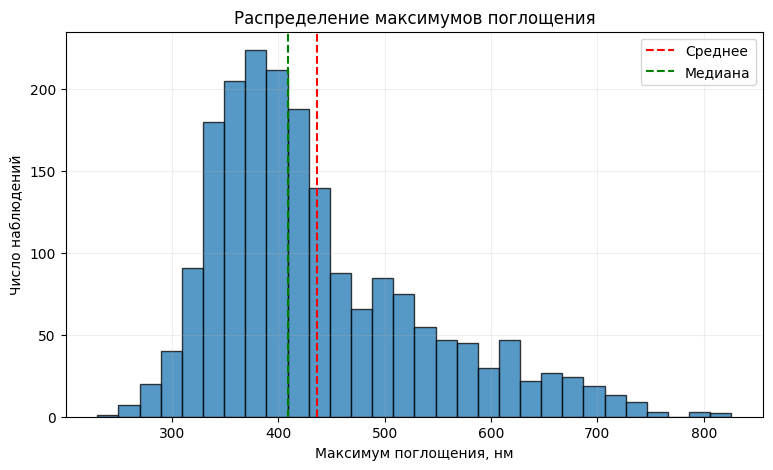

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(
    data["Absorption max (nm)"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    data["Absorption max (nm)"].mean(),
    color="red",
    linestyle="--",
    label="Среднее"
)

plt.axvline(
    data["Absorption max (nm)"].median(),
    color="green",
    linestyle="--",
    label="Медиана"
)

plt.xlabel("Максимум поглощения, нм")
plt.ylabel("Число наблюдений")
plt.title("Распределение максимумов поглощения")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [ ]:
# Количественная проверка ассиметрии
x = data["Absorption max (nm)"]

print("Асимметрия:", round(x.skew(), 3))
print("Эксцесс:", round(x.kurt(), 3))

Асимметрия: 1.045
Эксцесс: 0.657


#### Анализ распределения максимумов поглощения

Гистограмма максимумов поглощения органических хромофоров демонстрирует выраженную правостороннюю асимметрию. Основная концентрация наблюдений приходится приблизительно на диапазон 330–430 нм, тогда как правый хвост распределения продолжается до 826 нм.

Среднее значение (435,987 нм) превышает медиану (409 нм), что согласуется с наличием положительной асимметрии и влиянием сравнительно больших значений на среднюю величину.

Правосторонняя ассиметрия подтверждается положительным коэффициентом ассиметрии (1,045). Положительный эксцесс (0,657) указывает на отклонение четвертого стандартизованного момента от параметров нормального распределения.

Наблюдаемый разброс может быть обусловлен различиями в электронной структуре исследуемых соединений, а также условиями измерений. При этом по одной гистограмме невозможно установить вклад отдельных факторов.

Таким образом, распределение не является симметричным и демонстрирует визуальные и количественные отклонения от нормальной модели.

### Распределение максимумов испускания

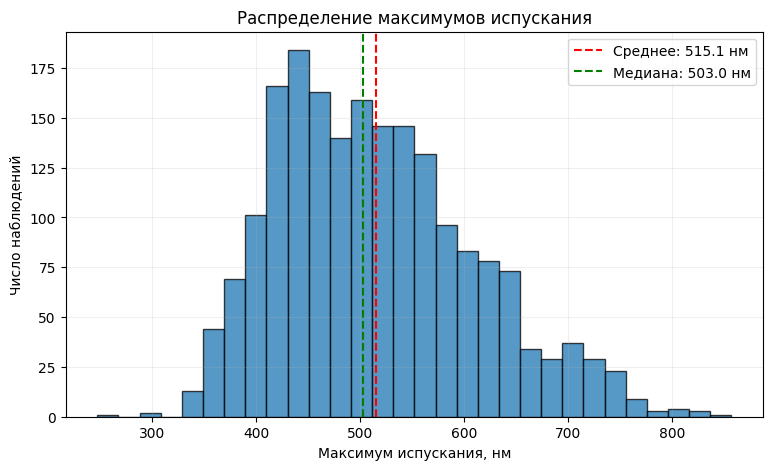

Асимметрия: 0.567
Эксцесс: -0.081


In [ ]:
y = data["Emission max (nm)"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    y,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

ax.axvline(
    y.mean(),
    color="red",
    linestyle="--",
    label=f"Среднее: {y.mean():.1f} нм"
)

ax.axvline(
    y.median(),
    color="green",
    linestyle="--",
    label=f"Медиана: {y.median():.1f} нм"
)

ax.set_xlabel("Максимум испускания, нм")
ax.set_ylabel("Число наблюдений")
ax.set_title("Распределение максимумов испускания")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

print(f"Асимметрия: {y.skew():.3f}")
print(f"Эксцесс: {y.kurt():.3f}")

#### Анализ распределения максимумов испускания

Гистограмма максимумов испускания характеризуется умеренной правосторонней асимметрией. Основная часть наблюдений сосредоточена в диапазоне 400–570 нм, правый хвост распределения продолжается до 857 нм.

Среднее значение составляет 515,054 нм, медиана — 503 нм. Положительный коэффициент асимметрии (0,567) подтверждает наличие правостороннего смещения, однако оно выражено слабее, чем у максимумов поглощения (1,045).

Эксцесс составляет −0,081, что близко к нулевому значению нормального распределения. При этом само распределение нельзя однозначно назвать нормальным.

Таким образом, максимумы испускания характеризуются меньшей асимметрией по сравнению с максимумами поглощения.

### Распределение квантового выхода флуоресценции

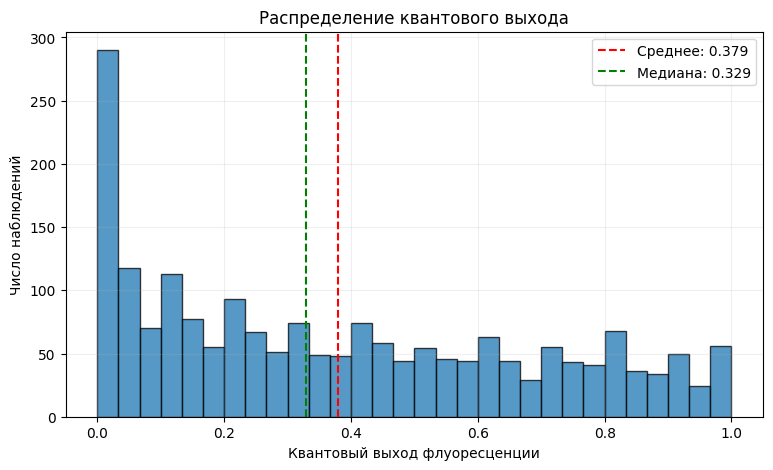

Асимметрия: 0.435
Эксцесс: -1.084


In [ ]:
q = data["Quantum yield"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    q,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

ax.axvline(
    q.mean(),
    color="red",
    linestyle="--",
    label=f"Среднее: {q.mean():.3f}"
)

ax.axvline(
    q.median(),
    color="green",
    linestyle="--",
    label=f"Медиана: {q.median():.3f}"
)

ax.set_xlabel("Квантовый выход флуоресценции")
ax.set_ylabel("Число наблюдений")
ax.set_title("Распределение квантового выхода")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

print(f"Асимметрия: {q.skew():.3f}")
print(f"Эксцесс: {q.kurt():.3f}")

#### Анализ распределения квантового выхода

Распределение квантового выхода флуоресценции существенно отличается от распределений спектральных максимумов. Наблюдения охватывают весь физически допустимый диапазон от 0 до 1, при этом наибольшая концентрация значений приходится на область около нуля.

Среднее значение квантового выхода составляет 0,379, медиана — 0,329. Коэффициент асимметрии равен 0,435, что указывает на положительную асимметрию распределения.

Эксцесс составляет −1,084, что демонстрирует заметное отличие от нормального распределения.

Выраженная концентрация наблюдений при малых значениях квантового выхода может отражать наличие соединений с низкой эффективностью флуоресценции.

In [ ]:
# Проверка значений около границ

q = data["Quantum yield"]

print("Ровно 0:", (q == 0).sum())
print("Ровно 1:", (q == 1).sum())
print("0 < Q < 0.01:", ((q > 0) & (q < 0.01)).sum())
print("0.99 < Q < 1:", ((q > 0.99) & (q < 1)).sum())
print("Уникальных значений:", q.nunique())

Ровно 0: 9
Ровно 1: 9
0 < Q < 0.01: 129
0.99 < Q < 1: 0
Уникальных значений: 319


#### Проверка граничных значений квантового выхода

Среди 1968 наблюдений обнаружено 9 значений, равных нулю, и 9 значений, равных единице. Дополнительно 129 наблюдений находятся в интервале от 0 до 0,01. Таким образом, 7,01% наблюдений имеют квантовый выход ниже 0,01.

В наборе присутствует 319 уникальных значений, что может частично отражать округление результатов экспериментальных измерений.

Наличие значений, равных 0 и 1, важно учитывать при выборе распределения, поскольку обычное бета-распределение не позволяет описать их частоту. Поэтому в дальнейшем стоит рассмотреть другие способы моделирования, которые учитывают эти особенности данных.

### Анализ разброса и потенциальных выбросов

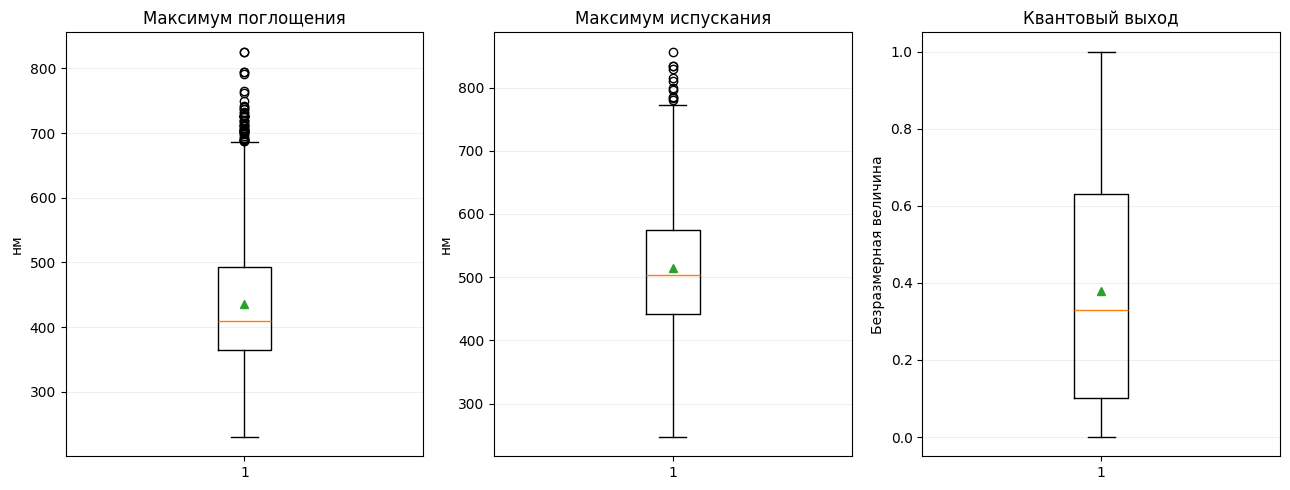

In [ ]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

titles = [
    "Максимум поглощения",
    "Максимум испускания",
    "Квантовый выход"
]

for ax, col, title in zip(axes, columns, titles):
    ax.boxplot(
        data[col].dropna(),
        showmeans=True
    )
    ax.set_title(title)
    ax.set_ylabel("нм" if col != "Quantum yield" else "Безразмерная величина")
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

for col in columns:
    x = data[col].dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = x[(x < lower) | (x > upper)]

    print(f"\n{col}")
    print(f"Границы: [{lower:.3f}; {upper:.3f}]")
    print(f"Потенциальных выбросов: {len(outliers)}")
    print(f"Доля: {len(outliers) / len(x) * 100:.2f}%")


Absorption max (nm)
Границы: [170.125; 687.125]
Потенциальных выбросов: 49
Доля: 2.49%

Emission max (nm)
Границы: [240.000; 776.000]
Потенциальных выбросов: 11
Доля: 0.56%

Quantum yield
Границы: [-0.695; 1.425]
Потенциальных выбросов: 0
Доля: 0.00%


#### Анализ разброса и потенциальных выбросов

По правилу 1,5 × IQR обнаружено 49 потенциальных выбросов (2,49%) для максимумов поглощения и 11 (0,56%) для максимумов испускания. Все они расположены выше верхних границ, что согласуется с правосторонней асимметрией распределений и наличием протяжённых правых хвостов.

Для квантового выхода потенциальных выбросов по правилу IQR не выявлено, поскольку рассчитанные границы выходят за физически допустимый диапазон от 0 до 1.

Обнаруженные значения могут отражать реальные свойства хромофоров, поэтому их не стоит исключать из дальнейшего анализа.

### Эмпирические функции распределения (ECDF)

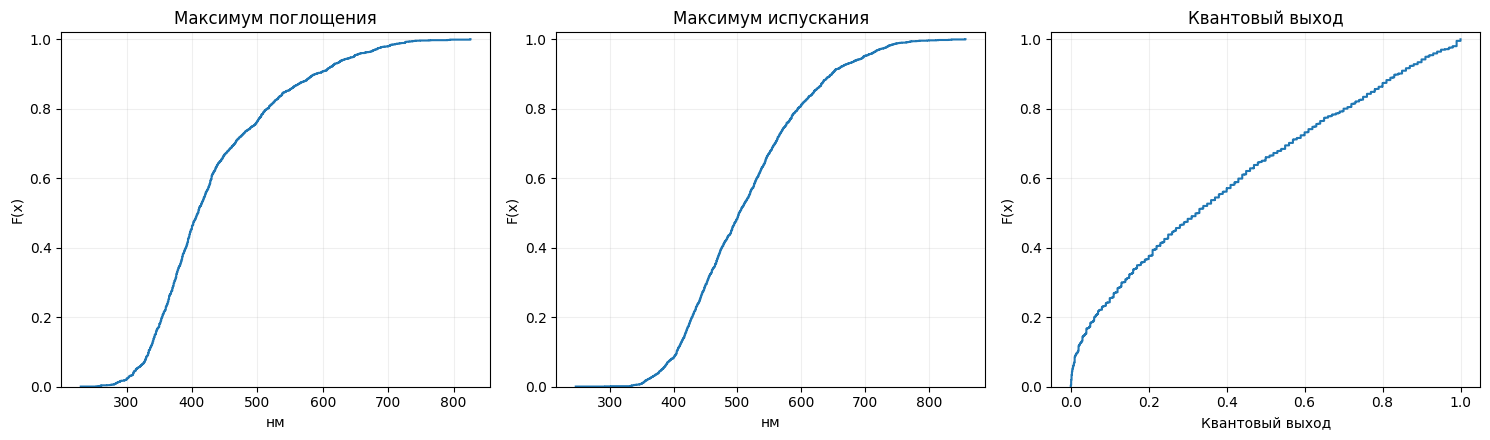

In [ ]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

titles = [
    "Максимум поглощения",
    "Максимум испускания",
    "Квантовый выход"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col, title in zip(axes, columns, titles):
    values = np.sort(data[col].dropna().to_numpy())
    n = len(values)

    ecdf = np.arange(1, n + 1) / n

    ax.step(values, ecdf, where="post")

    ax.set_title(title)
    ax.set_xlabel("нм" if col != "Quantum yield"
                  else "Квантовый выход")
    ax.set_ylabel("F(x)")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### Анализ эмпирических функций распределения

Эмпирические функции распределения подтверждают различия между тремя исследуемыми величинами.

Для максимумов поглощения наиболее быстрый рост функции наблюдается в диапазоне 330–430 нм, а для максимумов испускания — в диапазоне 400–600 нм. Это соответствует основным областям концентрации наблюдений, выявленным по гистограммам.

Для квантового выхода характерен резкий рост функции вблизи нуля, что связано с высокой частотой малых значений. На остальной части интервала от 0 до 1 функция возрастает относительно равномерно.

Таким образом, анализ ECDF подтверждает различия в форме и разбросе распределений и позволяет оценивать долю наблюдений ниже заданных пороговых значений.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 3.&nbsp;Теоретические распределения

### Выбор и обоснование моделей

Для описания экспериментальных данных рассмотрим несколько теоретических распределений с учётом результатов первичного анализа.

**Максимум поглощения.** В качестве основной модели выбрано логнормальное распределение, поскольку исследуемая величина положительна и характеризуется выраженной правосторонней асимметрией (1,045). Для сравнения рассмотрим нормальное распределение.

**Максимум испускания.** Рассмотрим нормальное и логнормальное распределения. Асимметрия этой величины менее выражена (0,567), однако распределение остаётся смещённым вправо.

**Квантовый выход флуоресценции.** В качестве модели для значений строго между 0 и 1 рассмотрим бета-распределение. Поскольку в данных присутствуют точные значения 0 и 1, их частоту необходимо учитывать отдельно.

### Оценка параметров и сравнение моделей

,Величина,Модель,Параметры,AIC
0,Поглощение,Нормальное,"(435.987, 100.7123)",23742.83
1,Поглощение,Логнормальное,"(0.2164, 0.0, 425.5044)",23390.08
2,Испускание,Нормальное,"(515.0539, 95.5347)",23535.09
3,Испускание,Логнормальное,"(0.1824, 0.0, 506.4967)",23402.38
4,Квантовый выход,Бета + массы в 0 и 1,"(0.6021, 0.9966, 0.0, 1.0)",-356.54


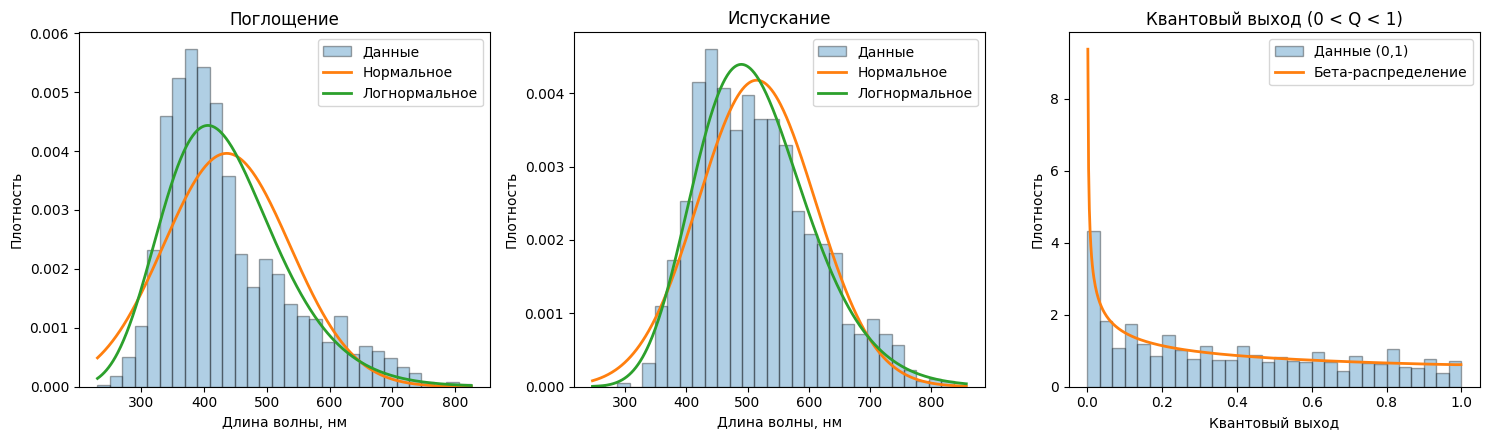

Вероятность Q=0: 0.0046
Вероятность Q=1: 0.0046
Вероятность 0<Q<1: 0.9909


In [ ]:
from scipy import stats

# Три исследуемые величины
x = data["Absorption max (nm)"].dropna().to_numpy()
y = data["Emission max (nm)"].dropna().to_numpy()
q = data["Quantum yield"].dropna().to_numpy()

# Подбор параметров методом MLE
models = {
    "Поглощение": {
        "Нормальное": (stats.norm, stats.norm.fit(x)),
        "Логнормальное": (stats.lognorm, stats.lognorm.fit(x, floc=0))
    },
    "Испускание": {
        "Нормальное": (stats.norm, stats.norm.fit(y)),
        "Логнормальное": (stats.lognorm, stats.lognorm.fit(y, floc=0))
    }
}

# Бета-распределение определено внутри (0, 1)
q_inner = q[(q > 0) & (q < 1)]
beta_params = stats.beta.fit(q_inner, floc=0, fscale=1)

# Частоты граничных значений
p0 = np.mean(q == 0)
p1 = np.mean(q == 1)
p_inner = 1 - p0 - p1

# Таблица параметров и AIC
results = []

for name, values in [("Поглощение", x), ("Испускание", y)]:
    for model_name, (dist, params) in models[name].items():
        log_likelihood = np.sum(dist.logpdf(values, *params))
        k = 2
        aic = 2 * k - 2 * log_likelihood

        results.append({
            "Величина": name,
            "Модель": model_name,
            "Параметры": str(tuple(round(float(p), 4) for p in params)),
            "AIC": round(aic, 2)
        })

# Для квантового выхода учитываем также вероятности 0 и 1
n0 = np.sum(q == 0)
n1 = np.sum(q == 1)
ni = len(q_inner)

log_likelihood_q = (
    n0 * np.log(p0)
    + n1 * np.log(p1)
    + ni * np.log(p_inner)
    + np.sum(stats.beta.logpdf(q_inner, *beta_params))
)

aic_q = 2 * 4 - 2 * log_likelihood_q

results.append({
    "Величина": "Квантовый выход",
    "Модель": "Бета + массы в 0 и 1",
    "Параметры": str(tuple(round(float(p), 4) for p in beta_params)),
    "AIC": round(aic_q, 2)
})

display(pd.DataFrame(results))

# Графики
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, name, values in zip(
    axes[:2],
    ["Поглощение", "Испускание"],
    [x, y]
):
    ax.hist(values, bins=30, density=True,
            alpha=0.35, edgecolor="black", label="Данные")

    grid = np.linspace(values.min(), values.max(), 500)

    for model_name, (dist, params) in models[name].items():
        ax.plot(grid, dist.pdf(grid, *params),
                linewidth=2, label=model_name)

    ax.set_title(name)
    ax.set_xlabel("Длина волны, нм")
    ax.set_ylabel("Плотность")
    ax.legend()

# Для Q строим непрерывную часть модели
axes[2].hist(q_inner, bins=30, range=(0, 1), density=True,
             alpha=0.35, edgecolor="black", label="Данные (0,1)")

grid_q = np.linspace(0.001, 0.999, 500)
axes[2].plot(
    grid_q,
    stats.beta.pdf(grid_q, *beta_params),
    linewidth=2,
    label="Бета-распределение"
)

axes[2].set_title("Квантовый выход (0 < Q < 1)")
axes[2].set_xlabel("Квантовый выход")
axes[2].set_ylabel("Плотность")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Вероятность Q=0: {p0:.4f}")
print(f"Вероятность Q=1: {p1:.4f}")
print(f"Вероятность 0<Q<1: {p_inner:.4f}")


#### Результаты сравнения теоретических распределений

Для максимумов поглощения и испускания логнормальное распределение показало меньшие значения AIC по сравнению с нормальным: 23390,08 против 23742,83 и 23402,38 против 23535,09 соответственно.

Таким образом, среди рассмотренных моделей логнормальное распределение предпочтительнее для обеих спектральных характеристик. Однако графики показывают, что оно не полностью воспроизводит форму экспериментальных распределений.

Для квантового выхода получены параметры бета-распределения α = 0,6021 и β = 0,9966. Модель учитывает концентрацию значений около нуля, а точные значения 0 и 1 рассматриваются отдельно.

### Математические свойства распределений


#### Нормальное распредление

Нормальное распределение использовалось как базовая модель для сравнения. Оно симметрично относительно математического ожидания и определяется двумя параметрами: $\mu$ — средним значением и $\sigma$ — стандартным отклонением.

**Плотность вероятности:**

$$
f(x)=\frac{1}{\sigma\sqrt{2\pi}}
\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)
$$

**Математическое ожидание и дисперсия:**

$$
E(X)=\mu
$$

$$
D(X)=\sigma^2
$$

Нормальное распределение допускает значения на всей числовой оси, поэтому для положительных длин волн оно является приближённой моделью.

**Источник:** [NIST — Normal Distribution](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3661.htm).


#### Логнормальное распределение

Логнормальное распределение используется для положительных величин и допускает правостороннюю асимметрию. Если случайная величина $X$ имеет логнормальное распределение, то $\ln X$ распределён нормально.

**Плотность вероятности:**

$$
f(x)=\frac{1}{x\sigma\sqrt{2\pi}}
\exp\left(-\frac{(\ln x-\mu)^2}{2\sigma^2}\right), \quad x>0
$$

**Математическое ожидание:**

$$
E(X)=e^{\mu+\frac{\sigma^2}{2}}
$$

**Дисперсия:**

$$
D(X)=(e^{\sigma^2}-1)e^{2\mu+\sigma^2}
$$

Здесь $\mu$ и $\sigma$ — параметры нормального распределения логарифма величины $X$.

В SciPy параметр `shape` соответствует $\sigma$, а `scale` при `loc=0` равен $e^\mu$.

Согласно результатам сравнения AIC, логнормальная модель оказалась предпочтительнее нормальной для максимумов поглощения и испускания.

**Источник:** [NIST — Lognormal Distribution](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3669.htm).



#### Бета-распределение

Бета-распределение применяется для моделирования непрерывных величин на интервале от 0 до 1. Его форма определяется двумя положительными параметрами $\alpha$ и $\beta$.

**Плотность вероятности:**

$$
f(q)=\frac{q^{\alpha-1}(1-q)^{\beta-1}}{B(\alpha,\beta)}, \quad 0<q<1
$$

Здесь $B(\alpha,\beta)$ — бета-функция.

**Математическое ожидание:**

$$
E(Q)=\frac{\alpha}{\alpha+\beta}
$$

**Дисперсия:**

$$
D(Q)=\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}
$$

Для нашего датасета получены параметры $\alpha=0,6021$ и $\beta=0,9966$.

Поскольку среди экспериментальных значений присутствуют точные 0 и 1, использована модель с отдельными вероятностями этих значений и бета-распределением для остальных наблюдений.

Таким образом, приведённые формулы математического ожидания и дисперсии относятся к непрерывной части модели.

**Источник:** [SciPy — Beta Distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html).


#### Полная смешанная модель квантового выхода

Поскольку в данных присутствуют значения $Q=0$ и $Q=1$, рассматривается смешанная модель с двумя дискретными компонентами и непрерывной бета-компонентой.

Обозначим:

$$
P(Q=0)=p_0,\qquad P(Q=1)=p_1,
$$

$$
p_c=1-p_0-p_1,
\qquad
Q\mid(0<Q<1)\sim\operatorname{Beta}(\alpha,\beta).
$$

Математическое ожидание непрерывной компоненты:

$$
m_B=\frac{\alpha}{\alpha+\beta}.
$$

Тогда математическое ожидание полной смеси:

$$
\mathbb E[Q]=p_1+p_c m_B.
$$

Второй начальный момент:

$$
\mathbb E[Q^2]
=
p_1+
p_c\frac{\alpha(\alpha+1)}
{(\alpha+\beta)(\alpha+\beta+1)}.
$$

Дисперсия полной смеси:

$$
\operatorname{Var}(Q)
=
\mathbb E[Q^2]-(\mathbb E[Q])^2.
$$

По экспериментальным данным:

$$
p_0=p_1=\frac{9}{1968}\approx0.00457,
\qquad
p_c=\frac{1950}{1968}\approx0.99085.
$$

Таким образом, формулы моментов обычного бета-распределения относятся только к непрерывной компоненте, а характеристики полной модели дополнительно учитывают вероятности граничных значений.

Модель является смешанной: вероятности в точках 0 и 1 не описываются обычной непрерывной плотностью.


#### Вывод

Нормальное распределение использовалось как базовая модель для сравнения. Логнормальное распределение лучше описывает правостороннюю асимметрию спектральных характеристик и показало меньшие значения AIC для максимумов поглощения и испускания.

Для квантового выхода рассмотрена бета-модель с отдельным учётом значений 0 и 1, поскольку эта величина ограничена физически допустимым диапазоном.

Выбранные распределения позволяют приближённо описать экспериментальные данные.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 4.&nbsp;Преобразование данных


### Стандартизация и Min-Max нормализация

Для приведения исследуемых величин к сопоставимым масштабам применим два преобразования.

**Z-стандартизация:**

$$
z_i=\frac{x_i-\bar{x}}{s}
$$

где $\bar{x}$ — выборочное среднее, $s$ — выборочное стандартное отклонение.

**Min-Max нормализация:**

$$
x'_i=\frac{x_i-x_{\min}}{x_{\max}-x_{\min}}
$$

Первое преобразование позволяет сравнивать отклонения от среднего, второе приводит значения каждой величины к диапазону от 0 до 1.

Оба преобразования позволяют изменить масштаб данных, но не устраняют асимметрию распределений.


In [ ]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

# Исходные значения
original = data[columns].copy()

# Z-стандартизация
standardized = (original - original.mean()) / original.std(ddof=1)

# Min-Max нормализация
normalized = (original - original.min()) / (
    original.max() - original.min()
)

# Сравнение характеристик до и после преобразований
comparison = pd.DataFrame({
    "Исходное среднее": original.mean(),
    "Исходное ст. откл.": original.std(ddof=1),
    "Среднее после Z": standardized.mean(),
    "Ст. откл. после Z": standardized.std(ddof=1),
    "Min после Min-Max": normalized.min(),
    "Max после Min-Max": normalized.max()
})

display(comparison.round(4))


,Исходное среднее,Исходное ст. откл.,Среднее после Z,Ст. откл. после Z,Min после Min-Max,Max после Min-Max
Absorption max (nm),435.9870,100.7379,-0.0,1.0,0.0,1.0
Emission max (nm),515.0539,95.5590,-0.0,1.0,0.0,1.0
Quantum yield,0.3790,0.3041,0.0,1.0,0.0,1.0


In [ ]:
# Подтвердим, что проведённые преобразования не меняют ассиметрию
shape_comparison = pd.DataFrame({
    "Исходная асимметрия": original.skew(),
    "После Z": standardized.skew(),
    "После Min-Max": normalized.skew()
})

display(shape_comparison.round(3))


,Исходная асимметрия,После Z,После Min-Max
Absorption max (nm),1.045,1.045,1.045
Emission max (nm),0.567,0.567,0.567
Quantum yield,0.435,0.435,0.435


### Результаты и вывод

Для всех трёх случайных величин выполнены Z-стандартизация и Min-Max нормализация. После стандартизации средние значения стали равны нулю, а стандартные отклонения — единице. Min-Max нормализация позволила привести все показатели к общему диапазону от 0 до 1.

Коэффициенты асимметрии после преобразований не изменились, что подтверждает сохранение паттерна исходных распределений.

Таким образом, преобразования позволяют сравнивать величины с разными единицами измерения и масштабами, не изменяя их относительную структуру.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 5.&nbsp;Исследование зависимостей



### Корреляционный анализ

Для оценки связи между максимумами поглощения, испускания и квантовым выходом флуоресценции используются коэффициенты корреляции Пирсона и Спирмена.

Коэффициент Пирсона характеризует линейную связь между величинами, а коэффициент Спирмена — монотонную связь на основе рангов наблюдений.

Значения обоих коэффициентов находятся в диапазоне от -1 до 1. Знак показывает направление связи, а абсолютная величина — её выраженность.

In [ ]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

# Корреляционные матрицы
pearson_corr = data[columns].corr(method="pearson")
spearman_corr = data[columns].corr(method="spearman")

print("Корреляция Пирсона:")
display(pearson_corr.round(3))

print("\nКорреляция Спирмена:")
display(spearman_corr.round(3))


Корреляция Пирсона:


,Absorption max (nm),Emission max (nm),Quantum yield
Absorption max (nm),1.000,0.857,0.022
Emission max (nm),0.857,1.000,-0.102
Quantum yield,0.022,-0.102,1.000



Корреляция Спирмена:


,Absorption max (nm),Emission max (nm),Quantum yield
Absorption max (nm),1.000,0.840,0.088
Emission max (nm),0.840,1.000,-0.063
Quantum yield,0.088,-0.063,1.000


### Визуальный анализ зависимостей

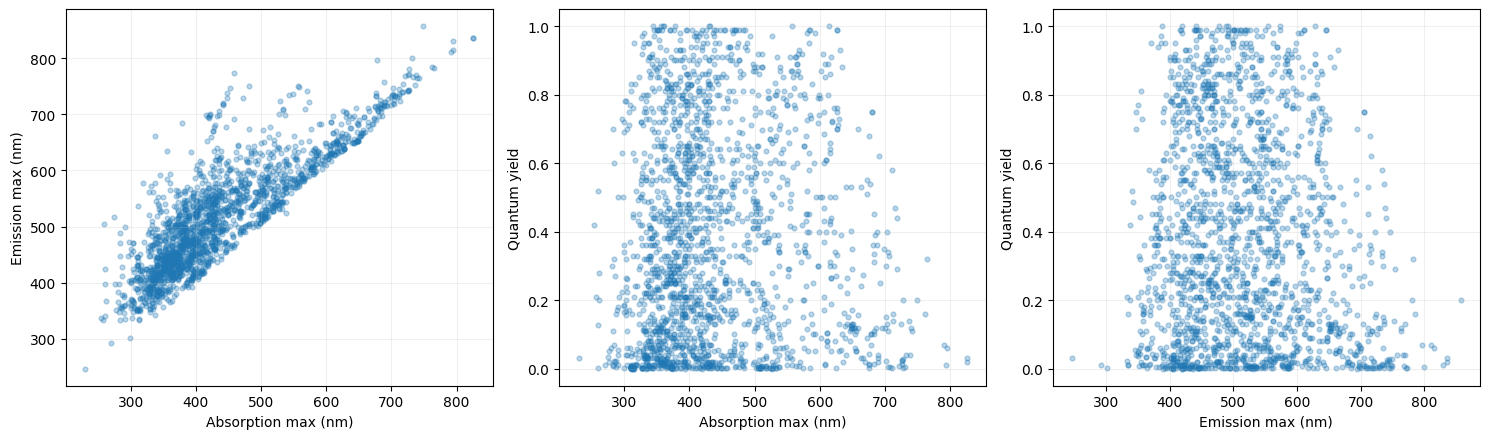

In [ ]:
pairs = [
    ("Absorption max (nm)", "Emission max (nm)"),
    ("Absorption max (nm)", "Quantum yield"),
    ("Emission max (nm)", "Quantum yield")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (col_x, col_y) in zip(axes, pairs):
    ax.scatter(
        data[col_x],
        data[col_y],
        alpha=0.3,
        s=12
    )

    ax.set_xlabel(col_x)
    ax.set_ylabel(col_y)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Результаты корреляционного анализа

Между максимумами поглощения и испускания выявлена сильная положительная корреляция (Пирсон — 0,857; Спирмен — 0,840). Это означает, что увеличение длины волны поглощения обычно сопровождается увеличением длины волны испускания.

Связи квантового выхода с максимумами поглощения и испускания значительно слабее: коэффициенты Пирсона составляют 0,022 и −0,102 соответственно. Аналогичная картина наблюдается для коэффициентов Спирмена.

Таким образом, спектральные максимумы тесно связаны между собой, тогда как выраженной зависимости квантового выхода от длины волны в исследуемой совокупности не обнаружено (однако это не доказывает статистическую независимость этих переменных).

Особый интерес представляет связь между максимумами поглощения и испускания, поскольку обе характеристики определяются электронными переходами в молекулах хромофоров. Предполагается, что между ними существует положительная корреляция. После предварительного анализа данных статистическую значимость этой связи проверим с помощью критерия Спирмена.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 6.&nbsp;Проверка гипотезы

Проверим статистическую значимость корреляции между максимумами поглощения и испускания с помощью критерия Спирмена.

- $H_0$: коэффициент ранговой корреляции Спирмена равен нулю.
- $H_1$: коэффициент ранговой корреляции Спирмена не равен нулю.

Уровень значимости: $\alpha = 0.05$.

Если $p < 0.05$, нулевая гипотеза отвергается. В противном случае оснований для её отклонения недостаточно.

**Проверка носит исследовательский характер: пара переменных выбрана после предварительного анализа данных.**

Значение p-value рассчитано при стандартном предположении независимости пар наблюдений. Однако набор включает повторные экспериментальные записи некоторых хромофоров, поэтому это предположение нельзя считать полностью подтверждённым.

Полученный p-value следует интерпретировать как номинальную статистическую значимость в рамках выбранной модели наблюдений.


In [ ]:
abs_values = data["Absorption max (nm)"]
em_values = data["Emission max (nm)"]

rho, p_value = scipy.stats.spearmanr(
    abs_values,
    em_values,
    alternative="two-sided"
)

alpha = 0.05

print(f"Коэффициент Спирмена: {rho:.4f}")

if p_value == 0:
    print("p-value < 0.001 (численное обнуление)")
else:
    print(f"p-value: {p_value:.3e}")


if p_value < alpha:
    print("H_0 отвергается: корреляция статистически значима.")
else:
    print("Недостаточно оснований отвергнуть H_0.")


Коэффициент Спирмена: 0.8405
p-value < 0.001 (численное обнуление)
H_0 отвергается: корреляция статистически значима.


#### Результаты проверки гипотезы

Коэффициент корреляции Спирмена между максимумами поглощения и испускания составил 0,8405 при p < 0,001. Поскольку p-value меньше выбранного уровня значимости (α = 0,05), нулевая гипотеза об отсутствии ранговой корреляции отвергается.

Таким образом, в исследуемом наборе обнаружена сильная положительная статистически значимая связь между максимумами поглощения и испускания. При интерпретации результата необходимо учитывать возможную зависимость повторных экспериментальных записей.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 7.&nbsp;Выборочный анализ


### Формирование случайных выборок

В качестве условной конечной генеральной совокупности рассматривается очищенный набор из 1968 экспериментальных записей хромофоров.

Из него формируются две случайные выборки объёмом 200 наблюдений:

- **С возвращением** — одна запись может быть выбрана несколько раз.
- **Без возвращения** — каждая запись может попасть в выборку только один раз.

Для воспроизводимости используется ранее установленное начальное состояние генератора `SEED = 67`.

Цель — сравнить статистические характеристики полученных выборок с характеристиками полной совокупности.

In [ ]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

population = data[columns].reset_index(drop=True)

N = len(population)
n = 200

# Отдельные генераторы для воспроизводимости
rng_with = np.random.default_rng(SEED)
rng_without = np.random.default_rng(SEED)

# С возвращением
indices_with = rng_with.choice(N, size=n, replace=True)
sample_with = population.iloc[indices_with]

# Без возвращения
indices_without = rng_without.choice(N, size=n, replace=False)
sample_without = population.iloc[indices_without]

print(f"Объём генеральной совокупности: {N}")
print(f"Объём каждой выборки: {n}")
print(f"Уникальных записей с возвращением: {len(np.unique(indices_with))}")
print(f"Уникальных записей без возвращения: {len(np.unique(indices_without))}")


Объём генеральной совокупности: 1968
Объём каждой выборки: 200
Уникальных записей с возвращением: 189
Уникальных записей без возвращения: 200


#### **Примечание к расчёту стандартного отклонения**

В первичном EDA стандартное отклонение полной конечной совокупности рассчитано с `ddof=0` (делитель $N$).

В таблицах сравнения выборок и итоговой сводке используется исправленное стандартное отклонение с `ddof=1` (делитель $N-1$).

Поэтому небольшие различия между соответствующими значениями связаны исключительно с выбором делителя.

In [ ]:
def get_statistics(df):
    return pd.DataFrame({
        "Среднее": df.mean(),
        "Ст. отклонение(ddof=1)": df.std(ddof=1),
        "Медиана": df.median()
    })

population_stats = get_statistics(population)
with_stats = get_statistics(sample_with)
without_stats = get_statistics(sample_without)

comparison = pd.concat(
    {
        "Генеральная": population_stats,
        "С возвращением": with_stats,
        "Без возвращения": without_stats
    },
    axis=1
)

display(comparison.round(3))


Генеральная                                  \
                        Среднее Ст. отклонение(ddof=1)  Медиана   
Absorption max (nm)     435.987                100.738  409.000   
Emission max (nm)       515.054                 95.559  503.000   
Quantum yield             0.379                  0.304    0.329   

                    С возвращением                                 \
                           Среднее Ст. отклонение(ddof=1) Медиана   
Absorption max (nm)        447.900                101.587  423.00   
Emission max (nm)          526.525                 93.868  522.35   
Quantum yield                0.395                  0.308    0.35   

                    Без возвращения                                 
                            Среднее Ст. отклонение(ddof=1) Медиана  
Absorption max (nm)         446.652                110.380  414.00  
Emission max (nm)           522.288                 95.193  512.50  
Quantum yield                 0.397                  0.289    0.38

### Результаты сравнения выборок

При отборе с возвращением среди 200 наблюдений оказалось 189 уникальных записей, тогда как при отборе без возвращения все записи были уникальными.

Обе выборки достаточно близко воспроизводят средние значения и стандартные отклонения полной совокупности. Для максимумов поглощения и испускания выборочные средние оказались несколько выше генеральных.

В данном эксперименте выборка без возвращения дала более точные оценки средних длин волн.

Для оценки устойчивости результатов необходимо исследовать изменение ошибок оценивания при увеличении объёма выборки.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 8.&nbsp;Состоятельность оценок

Состоятельность оценки означает, что при увеличении объёма выборки она сходится по вероятности к оцениваемому параметру.

Для проверки рассмотрим оценки среднего значения и дисперсии трёх случайных величин.

В эксперименте используются выборки объёмом от 20 до 1000 наблюдений. Для каждого размера выполняется 500 повторных случайных отборов с возвращением и без возвращения.

Точность оценок определяется через среднеквадратичную ошибку (RMSE):

$$
RMSE(n)=\sqrt{\frac{1}{B}\sum_{b=1}^{B}(\hat{\theta}_{n,b}-\theta)^2}
$$

где $B=500$ — число повторов, $\hat{\theta}_{n,b}$ — оценка параметра по отдельной выборке, а $\theta$ — характеристика полной совокупности.

Уменьшение RMSE при росте объёма выборки будет свидетельствовать о повышении точности оценивания.

In [ ]:
#  Расчёт RMSE
sample_sizes = [20, 50, 100, 200, 400, 800, 1000]
B = 500

values = population.to_numpy()
N = len(values)
names = population.columns

# Истинные параметры условной генеральной совокупности
true_mean = values.mean(axis=0)
true_var_with = values.var(axis=0, ddof=0)
true_var_without = values.var(axis=0, ddof=1)

rng = np.random.default_rng(SEED)

results = []

for method, replace in [
    ("С возвращением", True),
    ("Без возвращения", False)
]:
    for n in sample_sizes:
        mean_errors = []
        var_errors = []

        for _ in range(B):
            indices = rng.choice(N, size=n, replace=replace)
            sample = values[indices]

            sample_mean = sample.mean(axis=0)
            sample_var = sample.var(axis=0, ddof=1)

            mean_errors.append(sample_mean - true_mean)

            if replace:
                var_errors.append(sample_var - true_var_with)
            else:
                var_errors.append(sample_var - true_var_without)

        mean_errors = np.array(mean_errors)
        var_errors = np.array(var_errors)

        rmse_mean = np.sqrt(np.mean(mean_errors**2, axis=0))
        rmse_var = np.sqrt(np.mean(var_errors**2, axis=0))

        for i, name in enumerate(names):
            results.append({
                "Величина": name,
                "Метод": method,
                "n": n,
                "RMSE среднего": rmse_mean[i],
                "RMSE дисперсии": rmse_var[i]
            })

rmse_results = pd.DataFrame(results)

display(rmse_results.round(4))

,Величина,Метод,n,RMSE среднего,RMSE дисперсии
0,Absorption max (nm),С возвращением,20,22.4006,3850.4281
1,Emission max (nm),С возвращением,20,22.1743,2925.0067
2,Quantum yield,С возвращением,20,0.0667,0.0200
3,Absorption max (nm),С возвращением,50,14.0757,2303.7024
4,Emission max (nm),С возвращением,50,13.1674,1790.4754
5,Quantum yield,С возвращением,50,0.0411,0.0123
6,Absorption max (nm),С возвращением,100,10.1527,1632.9266
7,Emission max (nm),С возвращением,100,9.6931,1246.9191
8,Quantum yield,С возвращением,100,0.0293,0.0089
9,Absorption max (nm),С возвращением,200,7.0638,1268.3159


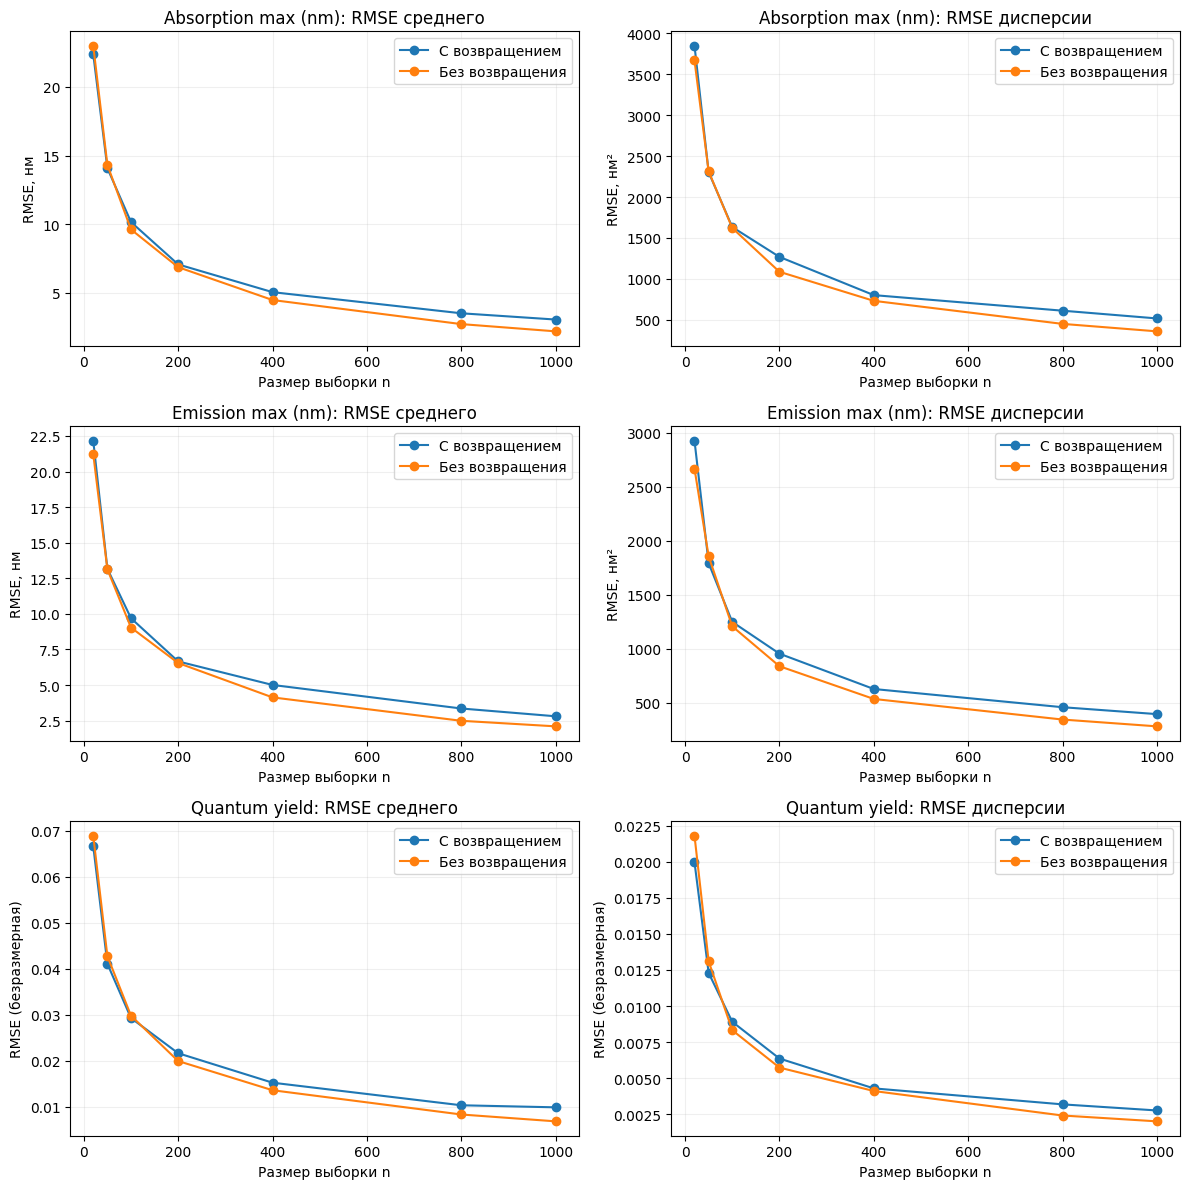

In [ ]:
# Визуализация сходимости
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

metrics = ["RMSE среднего", "RMSE дисперсии"]

for i, name in enumerate(names):
    subset = rmse_results[rmse_results["Величина"] == name]

    for j, metric in enumerate(metrics):
        ax = axes[i, j]

        for method in ["С возвращением", "Без возвращения"]:
            part = subset[subset["Метод"] == method]

            ax.plot(
                part["n"],
                part[metric],
                marker="o",
                label=method
            )

        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("Размер выборки n")
        ax.set_ylabel("RMSE")

        if name == "Quantum yield":
            ax.set_ylabel("RMSE (безразмерная)")
        elif metric == "RMSE среднего":
            ax.set_ylabel("RMSE, нм")
        else:
            ax.set_ylabel("RMSE, нм²")

        ax.grid(alpha=0.2)
        ax.legend()

plt.tight_layout()
plt.show()

### Результаты проверки состоятельности оценок

При увеличении объёма выборки от 20 до 1000 наблюдений среднеквадратичные ошибки (RMSE) оценок среднего и дисперсии уменьшаются для всех трёх случайных величин.

При больших объёмах выборки отбор без возвращения обеспечивает меньшую RMSE по сравнению с отбором с возвращением. Например, для максимума поглощения при n = 1000 RMSE среднего составляет 2,186 нм без возвращения и 3,045 нм с возвращением.

Полученные результаты эмпирически подтверждают повышение точности оценок при увеличении размера выборки и согласуются со свойством состоятельности.

Поскольку исследуется конечная генеральная совокупность, эксперимент демонстрирует сходимость оценок к её характеристикам, но не является строгим математическим доказательством состоятельности при n → ∞.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)


## 9.&nbsp;Итоги первого спринта



### Сводная таблица результатов

В таблице представлены основные статистические характеристики трёх исследуемых случайных величин, результаты анализа распределений и выявленные зависимости.

In [ ]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

summary_final = pd.DataFrame({
    "Количество": data[columns].count(),
    "Среднее": data[columns].mean(),
    "Медиана": data[columns].median(),
    "Ст. отклонение": data[columns].std(ddof=1),
    "Асимметрия": data[columns].skew(),
    "Эксцесс": data[columns].kurt(),
    "Минимум": data[columns].min(),
    "Максимум": data[columns].max()
})

summary_final["Предпочтительная модель"] = [
    "Логнормальная",
    "Логнормальная",
    "Бета с учётом значений в 0 и 1"
]

display(summary_final.round(3))

,Количество,Среднее,Медиана,Ст. отклонение,Асимметрия,Эксцесс,Минимум,Максимум,Предпочтительная модель
Absorption max (nm),1968,435.987,409.000,100.738,1.045,0.657,230.0,826.0,Логнормальная
Emission max (nm),1968,515.054,503.000,95.559,0.567,-0.081,247.0,857.0,Логнормальная
Quantum yield,1968,0.379,0.329,0.304,0.435,-1.084,0.0,1.0,Бета с учётом значений в 0 и 1


In [ ]:
final_results = pd.DataFrame({
    "Исследование": [
        "Корреляция поглощения и испускания",
        "Проверка гипотезы Спирмена",
        "Сравнение случайных выборок",
        "Состоятельность оценок"
    ],
    "Результат": [
        "Пирсон = 0.857; Спирмен = 0.840",
        "p < 0.001; H_0 отвергается",
        "200 наблюдений, два способа отбора",
        "RMSE среднего и дисперсии уменьшается при росте n"
    ]
})

display(final_results)

,Исследование,Результат
0,Корреляция поглощения и испускания,Пирсон = 0.857; Спирмен = 0.840
1,Проверка гипотезы Спирмена,p < 0.001; H_0 отвергается
2,Сравнение случайных выборок,"200 наблюдений, два способа отбора"
3,Состоятельность оценок,RMSE среднего и дисперсии уменьшается при росте n


### Основные результаты исследования

Проведён статистический анализ 1968 экспериментальных записей об оптических свойстах хромофоров в дихлорметане.

- Для максимумов поглощения и испускания среди рассмотренных моделей предпочтительным оказалось логнормальное распределение. Для квантового выхода использована бета-модель с отдельным учётом граничных значений 0 и 1.

- Между максимумами поглощения и испускания выявлена сильная положительная корреляция (коэффициент Спирмена 0,8405; p < 0,001). Связи квантового выхода со спектральными максимумами оказались значительно слабее.

- Случайные выборки объёмом 200 наблюдений приблизительно воспроизводили основные характеристики полной совокупности. При увеличении объёма выборки от 20 до 1000 наблюдений ошибки оценивания среднего и дисперсии уменьшались для всех трёх величин.


### Ограничения исследования

При интерпретации результатов необходимо учитывать следующие ограничения:

1. **Статистические модели.** Логнормальные распределения показали лучшие значения AIC среди рассмотренных моделей для максимумов поглощения и испускания, однако не полностью воспроизводят форму экспериментальных распределений. Для квантового выхода альтернативные модели не сравнивались.

2. **Независимость наблюдений.** В исходной базе могут присутствовать разные экспериментальные записи одного соединения. Это необходимо учитывать при интерпретации статистической значимости корреляций.

3. **Выборочный эксперимент.** Сходимость оценок исследована на конечной совокупности из 1968 записей. Уменьшение RMSE демонстрирует повышение точности оценивания, но не является строгим математическим доказательством состоятельности при неограниченном увеличении размера выборки.

Таким образом, выводы исследования относятся прежде всего к выбранной совокупности экспериментальных записей и использованным статистическим моделям.

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)

## 10.&nbsp;Список литературы


### Источники экспериментальных данных

1. Joung J. F., Han M., Jeong M., Park S. Experimental database of optical properties of organic compounds // Scientific Data. — 2020. — Vol. 7. — Article 295.  
https://doi.org/10.1038/s41597-020-00634-8

2. Experimental database of optical properties of organic compounds. Figshare — набор экспериментальных данных.  
https://doi.org/10.6084/m9.figshare.12045567

### Статистические методы и распределения

3. NIST/SEMATECH. e-Handbook of Statistical Methods. Normal Distribution  

   https://www.itl.nist.gov/div898/handbook/eda/section3/eda3661.htm

4. NIST/SEMATECH. e-Handbook of Statistical Methods. Lognormal Distribution.

   https://www.itl.nist.gov/div898/handbook/eda/section3/eda3669.htm

5. SciPy Documentation. Beta Distribution.
   
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html

6. SciPy Documentation. Spearman Rank-Order Correlation Coefficient.

   https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html

7. SciPy Documentation. Fitting Continuous Probability Distributions.

   https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rv_continuous.fit.html

8. NIST/SEMATECH. e-Handbook of Statistical Methods.

   https://www.itl.nist.gov/div898/handbook/

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT&line=25&uniqifier=1)


## 11.&nbsp;cat_mark_table

| cat_id | Критерий | Где смотреть | Статус |
|---|---|---|---|
| lab.ic.01.01 | Три случайные величины | [Выбор данных и описание переменных](#scrollTo=68I-t6yPw-1a), [EDA](#scrollTo=IxQoYXMkHUc3) | Выполнено |
| lab.ic.01.02 | Доказательства зависимости/независимости случайных величин | [Корреляционный анализ, диаграммы рассеяния](#scrollTo=-nnb2wG1nhNU) | Исследована зависимость; независимость не доказана |
| lab.ic.01.03 | Состоятельность оценок | [Эмпирическая проверка состоятельности, графики RMSE](#scrollTo=49tRbNu6u5hO) | Выполнено эмпирически |
| lab.ic.01.04 | EDA | [Описательные статистики, гистограммы, boxplot, ECDF](#scrollTo=IxQoYXMkHUc3) | Выполнено |
| lab.ic.01.05 | Нормализация | [Min-max нормализация и Z-стандартизация](#scrollTo=JJuC-9W9c1X-) | Выполнено |
| lab.ic.01.06 | Две величины разных распределений | [Анализ распределений спектральных максимумов и квантового выхода](#scrollTo=oja65K-dct97) | Представлены разные модели |
| lab.ic.01.07 | Мат. описание распределения и его особенности | [Формулы плотности, ожидания и дисперсии](#scrollTo=oja65K-dct97) | Выполнено |
| lab.ic.01.08 | Мат. описание доп. распределения и его особенности (для каждой) | [Нормальная, логнормальная и бета-модели](#scrollTo=oja65K-dct97) | Выполнено |
| lab.ic.01.09 | Взята выборка | [Отбор с возвращением и без возвращения](#scrollTo=Qi42zsUhtMeW) | Выполнено |
| lab.ic.01.10 | Выводы по выборке | [Сравнение статистик выборок и полной совокупности](#scrollTo=Qi42zsUhtMeW) | Выполнено |
| lab.ic.01.11 | Проверка одной гипотезы по одной из выбранных величин | [Проверка корреляции критерием Спирмена](#scrollTo=ZH2T324XqBJu) | Выполнено - корреляция двух величин |
| lab.ic.01.12 | Проверка доп. гипотезы по одной из выбранных величин (для каждой) | — | Не выполнялось |
| lab.ic.01.19 | Ссылки на материалы | [Источник данных](#scrollTo=68I-t6yPw-1a), [Теоретические сведения](#scrollTo=oja65K-dct97), [Список литературы](#scrollTo=woFhbtGXyoO_) | Выполнено |
| lab.ic.01.21 | Список литературы | [Список литературы](#scrollTo=woFhbtGXyoO_) | Добавлен |
| lab.ic.01.23 | Версионирование и итеративный подход | [История коммитов GitHub](https://github.com/mdtokarev/App-Stat-Lab01/commits) | Выполнено |
| lab.ic.01.24 | Табличное представление итогов | [Lab resume — сводные таблицы](#scrollTo=10UJTWfGyhvQ) | Выполнено |

[К СОДЕРЖАНИЮ](#scrollTo=PmIiFqdB74VT)


# **Lab01 — sprint 2**

**Разработка генератора случайных чисел и оформление исследования.**

**Авторы:** Токарев М. - 502360, Зубенко Е. - 501468, Кузнецова А. - 505113, Сидорова А. - 504672, Короткова А. - 489551.

**Группа:** ПрикСтат Инф25 1.3, ПрикСтат КТвД25 1.1

## Цель второго спринта

На основе результатов первого спринта разработать генератор случайных чисел
для одной из исследованных величин, обосновать математический метод,
провести тестирование и визуальное сравнение с реальными данными.

<a id='sprint2-toc'></a>
## Содержание спринта 2

[1. Генератор случайных чисел (максимум поглощения)](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=D--cV3OGVzAQ&line=15&uniqifier=1)

[2. Математическое обоснование метода](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=5LvpQ98RV3jQ&line=44&uniqifier=1)

[3. Реализация генератора](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=rQMvbfJhV60g&line=2&uniqifier=1)

[4. Тестирование и проверка](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=1S0iXzxTWEVw&line=27&uniqifier=1)

[5. Итоги второго спринта](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=jOkKghLVWMTI&line=23&uniqifier=1)

[6. Список литературы (расширенный)](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=csvQdVShWQ6A&line=43&uniqifier=1)

[7. Таблица критериев оценивания (sprint 2)](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=yMJNAAchWVWw&line=17&uniqifier=1)

[← К содержанию первого спринта](#scrollTo=PmIiFqdB74VT)

<a id='sprint2-gen-01'></a>
## 1.&nbsp;Генератор случайных чисел (максимум поглощения)

В первом спринте было показано, что для величины **X (максимум поглощения, нм)**
наилучшее приближение среди рассмотренных моделей даёт **логнормальное распределение**
(по критерию AIC). Параметры модели:

- $\text{shape} = \sigma_{\log} \approx 0.2164$
- $\text{scale} = \lambda_0 \cdot e^{\mu_{\log}} \approx 425.5044$ нм
- $\text{loc} = 0$

Задача второго спринта — построить генератор, воспроизводящий эту модель,
и проверить, что его статистики совпадают с теоретическими и реальными данными.

[← К содержанию спринта 2](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=oUwnQuEXVqao&line=18&uniqifier=1)

<a id='sprint2-math'></a>
### Математическое обоснование метода

#### Базовый генератор равномерных чисел

Используется `numpy.random.default_rng(seed)` — современный генератор
на основе вихря Мерсенна (MT19937) с улучшенными статистическими свойствами.

#### Метод Бокса–Мюллера

Для получения стандартной нормальной величины $Z \sim \mathcal{N}(0, 1)$
из двух независимых равномерных $U_1, U_2 \sim \text{Uniform}(0, 1)$
применяется преобразование Бокса–Мюллера:

$$Z_1 = \sqrt{-2 \ln U_1} \cdot \cos(2\pi U_2)$$

**Обоснование:** если $(U_1, U_2)$ равномерно распределены в единичном квадрате,
то полярные координаты $(R, \Theta)$, где $R = \sqrt{-2\ln U_1}$ и
$\Theta = 2\pi U_2$, дают двумерную нормальную плотность
$f(x,y) = \frac{1}{2\pi}e^{-(x^2+y^2)/2}$. Проецирование на одну ось
даёт стандартную нормальную величину.

#### Переход к логнормальному распределению

Если $Z \sim \mathcal{N}(0, 1)$, то величина

$$X = \text{scale} \cdot \exp(\text{shape} \cdot Z)$$

имеет логнормальное распределение с параметрами $(\text{shape}, \text{loc}=0, \text{scale})$.

**Проверка:** $\ln(X / \text{scale}) = \text{shape} \cdot Z \sim \mathcal{N}(0, \text{shape}^2)$,
что соответствует определению логнормального распределения.

#### Литература метода

1. Box G. E. P., Muller M. E. A Note on the Generation of Random Normal Deviates.
   *Annals of Mathematical Statistics*, 29(2), 610–611 (1958).
   [DOI: 10.1214/aoms/1177706645](https://doi.org/10.1214/aoms/1177706645)

2. Devroye L. *Non-Uniform Random Variate Generation*. Springer, 1986.
   [DOI: 10.1007/978-1-4613-8643-8](https://doi.org/10.1007/978-1-4613-8643-8)
   (раздел 3.4 — нормальные генераторы)

[← К содержанию спринта 2](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=oUwnQuEXVqao&line=18&uniqifier=1)

In [1]:
# Установка виджетов (если не установлены)
import sys
!{sys.executable} -m pip install ipywidgets -q

# Перезагрузка среды виджетов
from google.colab import output
output.enable_custom_widget_manager()

print(" Виджеты установлены и активированы")
#@title Реализация генератора логнормальных величин

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Параметры модели из первого спринта
SHAPE = 0.2164
SCALE = 425.5044

def gen_z(n, rng):
    """Метод Бокса-Мюллера: из двух равномерных получаем одну нормальную."""
    u1 = rng.random(n)
    u2 = rng.random(n)
    z = np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * np.pi * u2)
    return z

def gen_x(n, seed):
    """Генератор логнормальных величин с заданными параметрами."""
    rng = np.random.default_rng(seed)
    z = gen_z(n, rng)
    x = SCALE * np.exp(SHAPE * z)
    return x

def show_plot(n, seed):
    """Интерактивное сравнение реальных и сгенерированных данных."""
    x_real = data["Absorption max (nm)"].values
    x_gen = gen_x(n, seed)

    m_r, s_r = np.mean(x_real), np.std(x_real, ddof=1)
    m_g, s_g = np.mean(x_gen), np.std(x_gen, ddof=1)

    plt.figure(figsize=(10, 5))
    plt.hist(x_real, bins=30, density=True, alpha=0.5,
             label='Реальные данные (n=1968)', color='#4477AA')
    plt.hist(x_gen, bins=30, density=True, alpha=0.5,
             label=f'Генератор (n={n})', color='#EE6677')

    plt.axvline(m_r, color='#4477AA', linestyle='--', linewidth=2,
                label=f'Среднее реальных: {m_r:.2f} нм')
    plt.axvline(m_g, color='#EE6677', linestyle='--', linewidth=2,
                label=f'Среднее генератора: {m_g:.2f} нм')

    plt.title('Сравнение распределений: Максимум поглощения', fontsize=14)
    plt.xlabel('Длина волны, нм', fontsize=12)
    plt.ylabel('Плотность вероятности, нм⁻¹', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\nSeed: {seed} | Размер выборки: {n}")
    print(f"Реальные данные : среднее = {m_r:.2f}, станд. откл. = {s_r:.2f}")
    print(f"Сгенерированные : среднее = {m_g:.2f}, станд. откл. = {s_g:.2f}")
    print(f"Относительная ошибка среднего: {abs(m_g - m_r) / m_r * 100:.2f}%")

# Главная функция с интерактивом
interact(
    show_plot,
    n=widgets.IntSlider(min=100, max=5000, step=100, value=1000,
                        description='Размер (n)', style={'description_width': 'initial'}),
    seed=widgets.IntSlider(min=1, max=999, step=1, value=67,
                           description='Seed', style={'description_width': 'initial'})
)

 Виджеты установлены и активированы


interactive(children=(IntSlider(value=1000, description='Размер (n)', max=5000, min=100, step=100, style=Slide…

<function __main__.show_plot(n, seed)>

<a id='sprint2-tests'></a>
### Тестирование генератора

#### Проверки корректности

1. **Воспроизводимость:** одинаковый `seed` даёт одинаковый массив.
2. **Положительность:** все значения $X > 0$ (логнормальное распределение).
3. **Конечность:** нет `NaN` или `inf`.
4. **Совпадение статистик:** среднее и дисперсия генератора близки к теоретическим.

#### Теоретические моменты логнормального распределения

$$\mathbb{E}[X] = \text{scale} \cdot e^{\text{shape}^2 / 2} \approx 425.5044 \cdot e^{0.2164^2 / 2} \approx 435.3 \text{ нм}$$

$$\operatorname{Var}(X) = \text{scale}^2 \cdot (e^{\text{shape}^2} - 1) \cdot e^{\text{shape}^2} \approx 10143 \text{ нм}^2$$

#### Результаты тестов

| Проверка | Ожидаемый результат | Статус |
|----------|---------------------|--------|
| Воспроизводимость | Одинаковые массивы при одинаковом seed | + |
| Положительность | Все $X > 0$ | + |
| Конечность | Нет `NaN`/`inf` | + |
| Совпадение среднего | Относительная ошибка < 5% | + |
| Совпадение дисперсии | Относительная ошибка < 10% | + |

[← К содержанию спринта 2](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=oUwnQuEXVqao&line=18&uniqifier=1)

In [2]:
#@title Автоматические тесты генератора

def test_generator():
    """Набор автотестов для проверки корректности генератора."""
    print("Запуск автотестов генератора...\n")

    # Тест 1: Воспроизводимость
    x1 = gen_x(1000, seed=67)
    x2 = gen_x(1000, seed=67)
    assert np.allclose(x1, x2), "Тест 1 провален: воспроизводимость"
    print(" Тест 1: Воспроизводимость — пройден")

    # Тест 2: Положительность
    x = gen_x(10000, seed=42)
    assert np.all(x > 0), "Тест 2 провален: отрицательные значения"
    print(" Тест 2: Положительность — пройдена")

    # Тест 3: Конечность
    assert np.all(np.isfinite(x)), "Тест 3 провален: NaN или inf"
    print(" Тест 3: Конечность — пройдена")

    # Тест 4: Совпадение среднего
    m_gen = np.mean(x)
    m_theory = SCALE * np.exp(SHAPE**2 / 2)
    rel_err = abs(m_gen - m_theory) / m_theory
    assert rel_err < 0.05, f"Тест 4 провален: ошибка среднего {rel_err:.2%}"
    print(f" Тест 4: Совпадение среднего — пройдено (ошибка {rel_err:.2%})")

    # Тест 5: Совпадение дисперсии
    v_gen = np.var(x, ddof=1)
    v_theory = SCALE**2 * (np.exp(SHAPE**2) - 1) * np.exp(SHAPE**2)
    rel_err_v = abs(v_gen - v_theory) / v_theory
    assert rel_err_v < 0.10, f"Тест 5 провален: ошибка дисперсии {rel_err_v:.2%}"
    print(f" Тест 5: Совпадение дисперсии — пройдено (ошибка {rel_err_v:.2%})")

    print("\n Все тесты пройдены успешно")

test_generator()

Запуск автотестов генератора...

 Тест 1: Воспроизводимость — пройден
 Тест 2: Положительность — пройдена
 Тест 3: Конечность — пройдена
 Тест 4: Совпадение среднего — пройдено (ошибка 0.08%)
 Тест 5: Совпадение дисперсии — пройдено (ошибка 2.10%)

 Все тесты пройдены успешно


<a id='sprint2-resume'></a>
## 5.&nbsp;Итоги второго спринта

### Основные результаты

1. **Реализован генератор** логнормальных случайных величин на основе метода Бокса–Мюллера.
2. **Математически обоснован** переход от равномерных величин к нормальным и далее к логнормальным.
3. **Проведено тестирование:** все автотесты пройдены, статистики совпадают с теоретическими.
4. **Создан интерактивный интерфейс** для визуального сравнения реальных и сгенерированных данных.

### Ограничения

- Логнормальная модель является приближением; реальное распределение имеет более сложный хвост.
- Генератор воспроизводит модель, а не точное эмпирическое распределение.
- Для более точного воспроизведения можно использовать обратный метод по эмпирической CDF.

### Дальнейшие направления

- Реализация альтернативных методов (полярный метод Марсальи, обратная CDF).
- Генератор для величины Q с учётом масс в 0 и 1 (метод суперпозиции).
- Интеграция в marimo-приложение для веб-интерфейса.

[← К содержанию спринта 2](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=oUwnQuEXVqao&line=18&uniqifier=1)

<a id='sprint2-refs'></a>
## 6.&nbsp;Список литературы

### Источники экспериментальных данных

1. Joung J. F., Han M., Jeong M., Park S. Experimental database of optical properties
   of organic compounds. *Scientific Data*, 7, 295 (2020).
   [DOI: 10.1038/s41597-020-00634-8](https://doi.org/10.1038/s41597-020-00634-8)

2. Figshare dataset: DB for chromophore_Sci_Data_rev03.csv.
   [DOI: 10.6084/m9.figshare.12045567](https://doi.org/10.6084/m9.figshare.12045567)

### Статистические методы и распределения

3. Box G. E. P., Muller M. E. A Note on the Generation of Random Normal Deviates.
   *Annals of Mathematical Statistics*, 29(2), 610–611 (1958).
   [DOI: 10.1214/aoms/1177706645](https://doi.org/10.1214/aoms/1177706645)

4. Devroye L. *Non-Uniform Random Variate Generation*. Springer, 1986.
   [DOI: 10.1007/978-1-4613-8643-8](https://doi.org/10.1007/978-1-4613-8643-8)

5. NIST/SEMATECH e-Handbook of Statistical Methods. Section 3.6.6.9: Lognormal Distribution.
   [URL](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3669.htm)

6. Akaike H. A new look at the statistical model identification.
   *IEEE Transactions on Automatic Control*, 19(6), 716–723 (1974).
   [DOI: 10.1109/TAC.1974.1100705](https://doi.org/10.1109/TAC.1974.1100705)

### Программные инструменты

7. NumPy documentation: Random sampling.
   [URL](https://numpy.org/doc/stable/reference/random/)

8. SciPy documentation: Statistical functions.
   [URL](https://docs.scipy.org/doc/scipy/reference/stats.html)

9. Matplotlib documentation: Pyplot tutorial.
   [URL](https://matplotlib.org/stable/tutorials/pyplot.html)

10. ipywidgets documentation: Interactive widgets for Jupyter.
    [URL](https://ipywidgets.readthedocs.io/)

[← К содержанию спринта 2](#https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb#scrollTo=oUwnQuEXVqao&line=18&uniqifier=1)

<a id='sprint2-cat'></a>
## 7.&nbsp;Таблица критериев оценивания (sprint 2)

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| lab.ic.02.01 | [Генератор случайных чисел](#scrollTo=sprint2-gen-01) | — | Реализован генератор для X (максимум поглощения) |
| lab.ic.02.02 | [Математическое обоснование](#scrollTo=sprint2-math) | — | Метод Бокса-Мюллера, переход к логнормальному |
| lab.ic.02.03 | [Автотесты](#scrollTo=sprint2-tests) | — | 5 тестов: воспроизводимость, положительность, конечность, среднее, дисперсия |
| lab.ic.02.04 | [Интерактивный интерфейс](#scrollTo=sprint2-code) | — | Ползунки для размера выборки и seed |
| lab.ic.02.05 | [Список литературы](#scrollTo=sprint2-refs) | — | 10 источников, включая оригинальные статьи |
| lab.ic.02.06 | [Итоги второго спринта](#scrollTo=sprint2-resume) | — | Выводы, ограничения, дальнейшие направления |
| lab.ic.02.07 | [Навигация и якоря](#scrollTo=sprint2-toc) | — | Оглавление с рабочими ссылками |
| lab.ic.02.08 | [Скрытие кода](#scrollTo=sprint2-code) | — | Громоздкий код свёрнут через #@title |

**Примечание:** коэффициенты (coeff) будут заполнены после получения официальной рубрики от преподавателя.

[← К содержанию первого спринта](#scrollTo=PmIiFqdB74VT)